# Parte B — Model Training
**CDS3004 Data Mining · Diamond Ranked Games (10 min)**

**Research Question:** Can we predict the winning team in a League of Legends match using only statistics available after the first 10 minutes?

Questo notebook presenta il training di **Decision Tree, KNN e SVM (Linear e RBF)**, confrontati con una Baseline `DummyClassifier`. La Parte A è riutilizzata senza modifiche. Qui si leggono soltanto risultati di training/CV già prodotti: **nessun Test Set viene letto o valutato**.

La procedura completa si esegue dalla repository con `.venv/bin/python -B scripts/train_models.py --n-jobs 2`. Eseguire prima i test rapidi come indicato in `README_PART_B.md`. Il notebook non rilancia il training quando si esegue Run All.

## 1. Ambiente e caricamento dei risultati
Usare il kernel `.venv/bin/python` (Python 3.11). Il notebook funziona dalla repository o da `notebooks/`. La variabile `LOL_PART_B_RUN_ID` permette di mostrare un run rigenerato con un altro nome. Se gli artefatti non esistono, eseguire lo script di training; i soli JSON condivisi sono sufficienti per leggere i risultati aggregati.

In [1]:
import os
from pathlib import Path
import sys
import json
from hashlib import sha256

working_directory = Path.cwd().resolve()
repository_root = next(
    (folder for folder in [working_directory, *working_directory.parents]
     if (folder / "src/lol_model_training.py").is_file()), None
)
if repository_root is None:
    raise FileNotFoundError("Open this notebook inside the project repository.")
if str(repository_root) not in sys.path:
    sys.path.insert(0, str(repository_root))
os.environ.setdefault("MPLCONFIGDIR", str(repository_root / ".cache/part_b_matplotlib"))
Path(os.environ["MPLCONFIGDIR"]).mkdir(parents=True, exist_ok=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from src.lol_model_training import (
    DEFAULT_RUN_ID, METRIC_NAMES, MODEL_NAMES, load_run_results,
)

run_id = os.environ.get("LOL_PART_B_RUN_ID", DEFAULT_RUN_ID)
report_directory = repository_root / "reports/model_training" / run_id
results = load_run_results(root=repository_root, run_id=run_id)
metadata = results["metadata"]
comparison = results["comparison"].set_index("model").loc[list(MODEL_NAMES)]
outer_scores = results["outer_scores"]
best_params = results["best_params"]
assert metadata["status"] == "complete"
assert metadata["held_out_test_used"] is False
assert metadata["training_rows"] == 7903
assert metadata["cv"] == {"outer_folds": 5, "inner_folds": 3, "random_state": 42}
assert metadata["training_module_sha256"] == sha256(
    (repository_root / "src/lol_model_training.py").read_bytes()
).hexdigest(), "Training source changed since this run; investigate before presenting."
print("Run:", run_id)
print("Scope: 7,903 Diamond training matches; 12 unscaled input features")
print("Nested CV: 5 Outer / 3 Inner Folds; random_state=42")
display(pd.Series(metadata["packages"], name="training_version").to_frame())

Run: diamond_5x3_seed42
Scope: 7,903 Diamond training matches; 12 unscaled input features
Nested CV: 5 Outer / 3 Inner Folds; random_state=42


,training_version
joblib,1.6.0
numpy,2.1.3
pandas,2.2.3
scikit-learn,1.5.2
scipy,1.17.1
threadpoolctl,3.8.0


## 2. Riutilizzo della Parte A e isolamento del test
`load_training_data()` richiama la funzione originale `prepare_data()` e restituisce **soltanto** `prepared.X_train`, `prepared.y_train` e la provenienza. Il training ha ricevuto 7.903 record e 12 feature; il Test Set della Parte A rimane riservato.

`prepare_data()` controlla il checksum del CSV e ricostruisce lo split 80/20 stratificato con seed 42, dopo ordinamento per `gameId`. L'indice permette la tracciabilità ma non entra nei predictor. La target `blueWins` non entra in X. Non si rifanno EDA, Feature Selection, pulizia o gestione degli outlier.

Il contratto esistente crea anche gli oggetti test, ma i loro valori non vengono usati da nessuna operazione di training. I controlli sul manifest riguardano soltanto la struttura dello split. Le funzioni di training accettano `X_train` e `y_train`, senza argomenti per il test.

In [2]:
display(pd.Series({
    "source_sha256": metadata["source_sha256"],
    "training_rows": metadata["training_rows"],
    "training_classes": metadata["training_class_counts"],
    "target": metadata["target"],
    "positive_class": "1 = Blue wins",
    "held_out_test_used": metadata["held_out_test_used"],
    "training_data_sha256": metadata["training_data_sha256"],
}, name="training_contract").to_frame())
print("Feature order:", ", ".join(metadata["feature_names"]))

,training_contract
source_sha256,82b2e23279097c2dac616e966eb2911711c428d41b6382...
training_rows,7903
training_classes,"{'0': 3959, '1': 3944}"
target,blueWins
positive_class,1 = Blue wins
held_out_test_used,False
training_data_sha256,20067ba4e2664d75bb1db6996b32f3e96844c0a2e2d7a3...


Feature order: blueGoldDiff, blueExperienceDiff, killsDiff, assistsDiff, minionsDiff, jungleMinionsDiff, wardsPlacedDiff, wardsDestroyedDiff, firstBloodDiff, dragonsDiff, heraldsDiff, towersDestroyedDiff


## 3. Pipelines e Hyperparameter Tuning

| Famiglia | Pipeline | Hyperparameters |
|---|---|---|
| Baseline | `DummyClassifier(strategy="most_frequent")` | Nessun tuning |
| Decision Tree | `DecisionTreeClassifier` | `criterion`, `max_depth`, `min_samples_leaf` |
| KNN | `StandardScaler` → `KNeighborsClassifier` | `n_neighbors`, `weights`, `p` |
| SVM | `StandardScaler` → `SVC(probability=False)` | `kernel`, `C`; `gamma` soltanto per RBF |

Per ogni fit di CV, lo scaler impara media e deviazione standard dal solo Training Fold e applica quei parametri al Validation Fold. **Scalare tutto X_train prima della CV causerebbe Data Leakage.** Decision Tree non richiede scaling.

La Baseline usa esclusivamente la frequenza delle label del relativo Training Fold e ignora le relazioni fra X e y. È un riferimento, senza Hyperparameter Tuning. In questo campione predice Red, la classe leggermente più frequente.

I valori di k, profondità e regolarizzazione esplorano Underfitting/Overfitting. Le griglie sono fissate prima del training; non verranno ampliate sulla base del Test Set. Nella slide L7 lo scaling suggerito è in `[0,1]`; qui si usa `StandardScaler` come richiesto, che produce standardizzazione e non impone quell'intervallo.

In [3]:
display(pd.Series(metadata["candidate_counts"], name="candidate_configurations").to_frame())
print(json.dumps(metadata["search_space"], indent=2))
print("Total fits, including refits and Baseline:", metadata["expected_fit_count"])

,candidate_configurations
decision_tree,40
knn,24
svm,20


{
  "decision_tree": {
    "classifier__criterion": [
      "gini",
      "entropy"
    ],
    "classifier__max_depth": [
      3,
      5,
      8,
      12,
      null
    ],
    "classifier__min_samples_leaf": [
      1,
      5,
      10,
      20
    ]
  },
  "knn": {
    "classifier__n_neighbors": [
      3,
      5,
      11,
      21,
      41,
      81
    ],
    "classifier__p": [
      1,
      2
    ],
    "classifier__weights": [
      "uniform",
      "distance"
    ]
  },
  "svm": [
    {
      "classifier__C": [
        0.01,
        0.1,
        1,
        10
      ],
      "classifier__kernel": [
        "linear"
      ]
    },
    {
      "classifier__C": [
        0.01,
        0.1,
        1,
        10
      ],
      "classifier__gamma": [
        "scale",
        0.01,
        0.1,
        1
      ],
      "classifier__kernel": [
        "rbf"
      ]
    }
  ]
}
Total fits, including refits and Baseline: 1536


## 4. Nested Stratified Cross-Validation: 5 Outer × 3 Inner
1. Cinque Outer Folds dividono soltanto il Training Set, mantenendo approssimativamente le proporzioni delle classi.
2. Per ogni Outer Training Fold, una Grid Search a tre Inner Folds sceglie gli Hyperparameters usando la mean Accuracy.
3. La migliore Pipeline viene rifittata sull'Outer Training Fold e valutata sull'Outer Validation Fold, escluso dal tuning.
4. Tutti i modelli e la Baseline usano gli stessi Outer Folds; le ricerche condividono anche gli Inner Folds.
5. La famiglia viene scelta dalla **Outer mean Accuracy**, prima delle ricerche finali. Si rifanno poi ricerche a tre fold sul Training Set intero per ottenere i parametri finali e si salvano quattro modelli.

Parità esatte tra famiglie: minore SD, poi Decision Tree → KNN → SVM. La Baseline non partecipa alla selezione dei tre algoritmi appresi; un mancato miglioramento rispetto alla Baseline sarebbe segnalato.

Il miglior Inner CV score ha partecipato alla selezione e può essere ottimistico. Gli Outer scores valutano la procedura di tuning su Validation Folds esclusi da quella ricerca. Anche la scelta tra famiglie usa questi risultati: servirà ancora il Test Set indipendente per la valutazione finale. Il metodo è trattato in L6, slide 51, e L7, slide 23.

In [4]:
fold_accuracy = outer_scores.pivot(index="outer_fold", columns="model", values="accuracy")
display(fold_accuracy.loc[:, list(MODEL_NAMES)].map(lambda value: f"{value:.2%}"))
print("Each cell is an OUTER validation score; no held-out test score is shown.")

model,dummy,decision_tree,knn,svm
outer_fold,,,,
1,50.09%,74.45%,73.31%,74.95%
2,50.09%,69.51%,69.70%,70.59%
3,50.09%,69.64%,70.65%,72.11%
4,50.06%,72.22%,72.59%,73.80%
5,50.13%,72.09%,71.84%,73.29%


Each cell is an OUTER validation score; no held-out test score is shown.


## 5. Metriche e confronto dei modelli
**Accuracy** è il criterio principale: le classi sono quasi bilanciate e non sono definiti costi asimmetrici degli errori. Precision, Recall e F1 usano la classe positiva `1` (Blue wins), con `zero_division=0`. Non sono macro averages.

ROC-AUC usa `predict_proba` per Dummy/Decision Tree/KNN e `decision_function` per SVM. Non si abilita la calibrazione delle probabilità della SVM e non si ottimizzano soglie. Le metriche basate sulle classi usano `predict`.

La tabella riporta mean ± **sample SD (ddof=1)** sui cinque Outer Folds. La SD mostra la variabilità fra fold, non è un Confidence Interval e non dimostra significatività statistica. Nelle Grid Search, le SD interne di sklearn usano invece ddof=0.

In [5]:
metric_table = pd.DataFrame(index=comparison.index)
for metric in METRIC_NAMES:
    metric_table[metric] = [
        f"{row[f'mean_{metric}']:.4f} ± {row[f'std_{metric}']:.4f}"
        for _, row in comparison.iterrows()
    ]
display(metric_table)
selected = metadata["selected_model"]
selected_accuracy = comparison.loc[selected, "mean_accuracy"]
baseline_accuracy = comparison.loc["dummy", "mean_accuracy"]
gain = (selected_accuracy - baseline_accuracy) * 100
display(Markdown(
    f"La famiglia selezionata tramite Outer CV è **{selected.upper()}**, "
    f"con Accuracy media **{selected_accuracy:.2%}**. "
    f"Il miglioramento sulla Baseline è **{gain:.2f} punti percentuali**. "
    "Questa è una stima di Cross-Validation sul Training Set, non una Test Accuracy."
))

,accuracy,precision,recall,f1,roc_auc
model,,,,,
dummy,0.5009 ± 0.0002,0.0000 ± 0.0000,0.0000 ± 0.0000,0.0000 ± 0.0000,0.5000 ± 0.0000
decision_tree,0.7158 ± 0.0206,0.7216 ± 0.0315,0.7051 ± 0.0441,0.7121 ± 0.0212,0.7940 ± 0.0132
knn,0.7162 ± 0.0145,0.7145 ± 0.0188,0.7193 ± 0.0218,0.7167 ± 0.0141,0.7986 ± 0.0130
svm,0.7295 ± 0.0167,0.7284 ± 0.0160,0.7302 ± 0.0215,0.7292 ± 0.0175,0.8089 ± 0.0136


La famiglia selezionata tramite Outer CV è **SVM**, con Accuracy media **72.95%**. Il miglioramento sulla Baseline è **22.85 punti percentuali**. Questa è una stima di Cross-Validation sul Training Set, non una Test Accuracy.

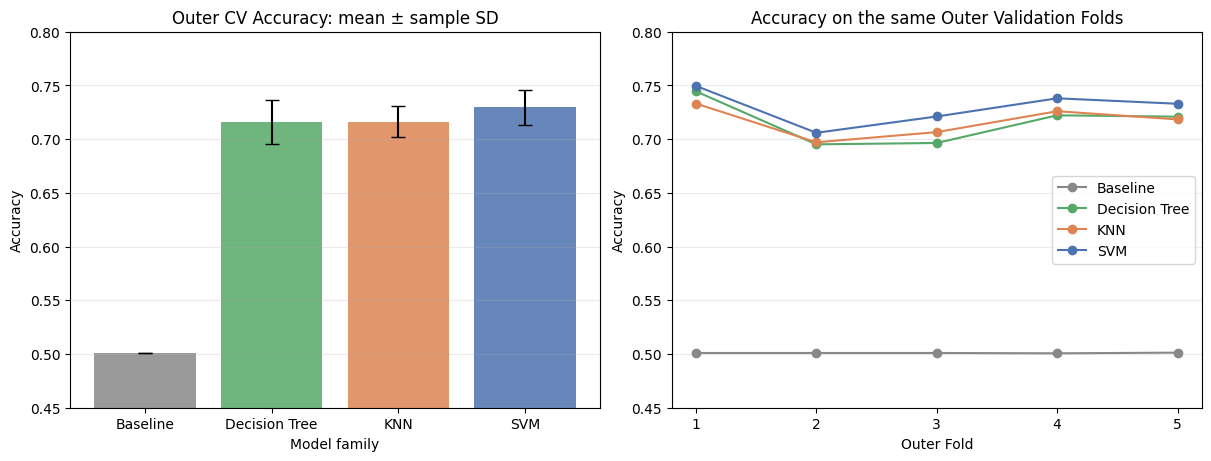

In [6]:
labels = ["Baseline", "Decision Tree", "KNN", "SVM"]
colors = ["#888888", "#55a868", "#dd8452", "#4c72b0"]
figure, axes = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)
positions = np.arange(len(labels))
axes[0].bar(positions, comparison.mean_accuracy, color=colors, alpha=0.85)
axes[0].errorbar(positions, comparison.mean_accuracy, yerr=comparison.std_accuracy,
                 fmt="none", color="black", capsize=5)
axes[0].set_xticks(positions, labels)
axes[0].set(title="Outer CV Accuracy: mean ± sample SD", xlabel="Model family",
            ylabel="Accuracy", ylim=(0.45, 0.80))
for name, label, color in zip(MODEL_NAMES, labels, colors):
    axes[1].plot(fold_accuracy.index, fold_accuracy[name], marker="o", color=color, label=label)
axes[1].set(title="Accuracy on the same Outer Validation Folds", xlabel="Outer Fold",
            ylabel="Accuracy", xticks=range(1, 6), ylim=(0.45, 0.80))
axes[1].legend()
for axis in axes:
    axis.grid(axis="y", alpha=0.25)
plt.show()
plt.close(figure)

### Interpretazione semplice
La Baseline si comporta come chi risponde sempre “vince Red”: ottiene circa il 50% perché le classi sono bilanciate. I modelli appresi usano invece le statistiche dei primi dieci minuti per migliorare la previsione.

Un'Accuracy CV attorno al 73% corrisponde, in media nei Validation Folds, a circa 73 vincitori corretti su 100 partite. Non è una garanzia per ogni gruppo di 100 partite né una percentuale già verificata sul test.

La Baseline può avere Precision/Recall/F1 pari a zero per Blue pur classificando correttamente circa metà delle partite: non predice mai Blue. ROC-AUC pari a 0.5 è coerente con l'assenza di capacità di ordinamento. L'AUC di una SVM non è la probabilità di vittoria di una singola partita.

Differenze piccole fra Decision Tree e KNN vanno descritte con cautela. Il modello più flessibile non è automaticamente migliore: la Grid Search prova sia confini lineari sia non lineari per SVM.

## 6. Hyperparameters finali e diagnostica della ricerca
I parametri seguenti sono scelti con una Grid Search a tre fold sull'intero Training Set, dopo aver congelato la scelta della famiglia. Ogni modello finale è già rifittato su tutte le 7.903 partite di training.

Gli Hyperparameters possono cambiare fra Outer Folds perché cambia il campione usato per il tuning. I punteggi delle ricerche finali sotto riportati sono **tuning scores**, distinti dagli Outer scores usati per confrontare le famiglie.

In [7]:
display(pd.DataFrame([
    {"model": name, "final_parameters": json.dumps(best_params[name], sort_keys=True)}
    for name in MODEL_NAMES
]).set_index("model"))
for name in ("decision_tree", "knn", "svm"):
    search_results = pd.DataFrame(json.loads(
        (report_directory / f"cv_results_{name}.json").read_text()
    ))
    display(Markdown(f"**{name}: cinque migliori configurazioni nella ricerca finale**"))
    display(search_results.sort_values("rank_test_accuracy", kind="stable")
            [["params", "mean_test_accuracy", "std_test_accuracy", "mean_test_roc_auc"]].head(5))

,final_parameters
model,
dummy,"{""classifier__strategy"": ""most_frequent""}"
decision_tree,"{""classifier__criterion"": ""entropy"", ""classifi..."
knn,"{""classifier__n_neighbors"": 81, ""classifier__p..."
svm,"{""classifier__C"": 10, ""classifier__kernel"": ""l..."


**decision_tree: cinque migliori configurazioni nella ricerca finale**

,params,mean_test_accuracy,std_test_accuracy,mean_test_roc_auc
27,"{'classifier__criterion': 'entropy', 'classifi...",0.720738,0.010910,0.797995
26,"{'classifier__criterion': 'entropy', 'classifi...",0.720105,0.010961,0.797617
0,"{'classifier__criterion': 'gini', 'classifier_...",0.717068,0.009370,0.791954
1,"{'classifier__criterion': 'gini', 'classifier_...",0.717068,0.009370,0.791954
2,"{'classifier__criterion': 'gini', 'classifier_...",0.717068,0.009370,0.791954


**knn: cinque migliori configurazioni nella ricerca finale**

,params,mean_test_accuracy,std_test_accuracy,mean_test_roc_auc
21,"{'classifier__n_neighbors': 81, 'classifier__p...",0.718840,0.007632,0.800387
20,"{'classifier__n_neighbors': 81, 'classifier__p...",0.718714,0.006242,0.800649
16,"{'classifier__n_neighbors': 41, 'classifier__p...",0.716689,0.006934,0.796496
22,"{'classifier__n_neighbors': 81, 'classifier__p...",0.715930,0.006702,0.798062
17,"{'classifier__n_neighbors': 41, 'classifier__p...",0.715424,0.006850,0.795756


**svm: cinque migliori configurazioni nella ricerca finale**

,params,mean_test_accuracy,std_test_accuracy,mean_test_roc_auc
3,"{'classifier__C': 10, 'classifier__kernel': 'l...",0.729596,0.007931,0.808346
2,"{'classifier__C': 1, 'classifier__kernel': 'li...",0.729216,0.007793,0.808372
1,"{'classifier__C': 0.1, 'classifier__kernel': '...",0.728710,0.008180,0.808479
0,"{'classifier__C': 0.01, 'classifier__kernel': ...",0.727066,0.007292,0.807223
17,"{'classifier__C': 10, 'classifier__gamma': 0.0...",0.725799,0.009601,0.803466


In [8]:
boundary_notes = []
knn_values = metadata["search_space"]["knn"]["classifier__n_neighbors"]
chosen_k = best_params["knn"]["classifier__n_neighbors"]
if chosen_k in (min(knn_values), max(knn_values)):
    boundary_notes.append(f"KNN: k={chosen_k} è al bordo della griglia testata.")
chosen_kernel = best_params["svm"]["classifier__kernel"]
svm_grid = next(g for g in metadata["search_space"]["svm"]
                if chosen_kernel in g["classifier__kernel"])
chosen_c = best_params["svm"]["classifier__C"]
if chosen_c in (min(svm_grid["classifier__C"]), max(svm_grid["classifier__C"])):
    boundary_notes.append(f"SVM: C={chosen_c} è al bordo della griglia testata.")
for note in boundary_notes:
    print(note)
print("Un optimum al bordo non dimostra un optimum globale. Non si amplia la griglia dopo aver visto il test.")
print("Runtime warnings recorded:", metadata["warnings"])
print(f"Full training runtime: {metadata['elapsed_seconds']:.1f} seconds (machine dependent)")

KNN: k=81 è al bordo della griglia testata.
SVM: C=10 è al bordo della griglia testata.
Un optimum al bordo non dimostra un optimum globale. Non si amplia la griglia dopo aver visto il test.
Runtime warnings recorded: []
Full training runtime: 119.5 seconds (machine dependent)


## 7. Artefatti, riproducibilità e passaggio alla Model Evaluation
Il codice riutilizzabile è in `src/lol_model_training.py`. I file `.joblib` contengono la Pipeline intera: il membro della Model Evaluation dovrà passarle **X_test non scalato**, senza rifittare modello o scaler. `load_final_model()` controlla checksum e versioni prima del caricamento. La scelta rimane quella di `selection.json`; il test non potrà essere usato per ritoccare parametri, soglie, feature o modello.

I CSV e i modelli sono ignorati dalla `.gitignore` originale. Per GitHub sono disponibili gli stessi risultati aggregati anche in JSON, oltre a notebook, codice, test e documentazione. Non contengono righe del dataset o predizioni individuali. Il manifest dei fold con gli ID delle partite resta locale in `data/processed/part_b/<run_id>/`.

Il membro successivo può **rigenerare** tutto con stesso CSV e dipendenze (`requirements-part-b.txt`), oppure ricevere privatamente le cartelle del run sotto `models/part_b/`, `reports/model_training/` e `data/processed/part_b/`, mantenendo i percorsi. Se il nome del run è già presente, usare un nuovo `--run-id`: non si sovrascrivono risultati esistenti.

Vedere `README_PART_B.md` e `reports/model_training_handoff.md` per i comandi e il contratto di valutazione. I test automatici controllano scaling per fold, appartenenza dei record a fit consentiti, ripetibilità, schema e caricamento degli artefatti. Il notebook non carica né valuta i modelli sul test.

In [9]:
artifact_rows = []
for name, artifact in metadata["model_files"].items():
    artifact_rows.append({"model": name, "relative_path": artifact["path"], "sha256": artifact["sha256"]})
display(pd.DataFrame(artifact_rows).set_index("model"))
print("Selected model frozen before final searches:")
print(json.dumps(json.loads((report_directory / "selection.json").read_text()), indent=2))
assert len(outer_scores) == 20
assert all(outer_scores.groupby("model").size() == 5)
for metric in METRIC_NAMES:
    assert outer_scores[metric].between(0, 1).all()
print("PASS: complete aggregate results for 4 models × 5 Outer Folds; no held-out test evaluation.")

,relative_path,sha256
model,,
decision_tree,models/part_b/diamond_5x3_seed42/decision_tree...,151b34dfa1ed91f5035872b473ba74f167dfa0a454b30d...
dummy,models/part_b/diamond_5x3_seed42/dummy.joblib,c017d92b62594555c5f1183a66b5adcf00da42c0c75cee...
knn,models/part_b/diamond_5x3_seed42/knn.joblib,2d65bc6f007571192b4b2a08dbbe95d33e6bf92b766290...
svm,models/part_b/diamond_5x3_seed42/svm.joblib,c4ce499e9b4b4901d9e5e7fab879e07e3f03bb9b20159f...


Selected model frozen before final searches:
{
  "held_out_test_used": false,
  "selected_model": "svm",
  "selection_rule": "maximum outer mean accuracy; exact ties: minimum sample SD, then decision_tree/knn/svm",
  "selection_source": "Outer CV scores only; frozen before final searches"
}
PASS: complete aggregate results for 4 models × 5 Outer Folds; no held-out test evaluation.


## 8. Limiti e conclusione per la presentazione
Le statistiche a dieci minuti mostrano capacità predittiva rispetto alla Baseline nel Training Set Diamond. Le conclusioni riguardano soltanto questo campione, le 12 feature della Parte A e le griglie provate; la Model Evaluation indipendente deve ancora essere svolta.

Restano i limiti già documentati: ward count estremi non risolti, feature correlate, assenza di player ID e patch/time metadata, perdita del ritmo assoluto con le differenze Blue−Red. `StandardScaler` non risolve questi problemi e può essere sensibile agli outlier. Non sono state aggiunte nuove regole di pulizia o Feature Selection.

La selezione tra famiglie usa gli Outer scores e può rendere ottimistico il punteggio del vincitore. La SD su cinque fold non è una prova di significatività. La futura valutazione sul test fornirà una stima separata senza riaprire la selezione. Non sono state svolte analisi Challenger, Clustering o Association Rule Mining.